# Case C · Monthly demand forecasting

## CRISP-DM question

Can a simple seasonal model improve a one-year operational plan over last
year's same-month baseline?

**Learning objective:** keep chronology intact, create forecasts from past
information only, and compare models with MAE and MAPE.


In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

from tutorial.data import write_datasets

plt.rcParams.update({
    "figure.dpi": 150,
    "font.family": "serif",
    "font.serif": ["Times New Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "axes.grid": True,
    "grid.color": "#c8c8c8",
    "grid.linewidth": 0.5,
    "grid.alpha": 0.7,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 10,
    "axes.titlesize": 10.5,
    "lines.linewidth": 1.4,
})

paths = write_datasets(ROOT / "data")
print(f"Project root: {ROOT.name}")

Project root: data-science-crisp-dm-tutorial


In [2]:
df = pd.read_csv(paths["demand"], parse_dates=["month"])
df.tail()

,month,demand
55,2025-08-01,172.5
56,2025-09-01,173.3
57,2025-10-01,185.3
58,2025-11-01,177.5
59,2025-12-01,194.5


<Axes: title={'center': 'Synthetic monthly demand'}, xlabel='month', ylabel='Demand'>

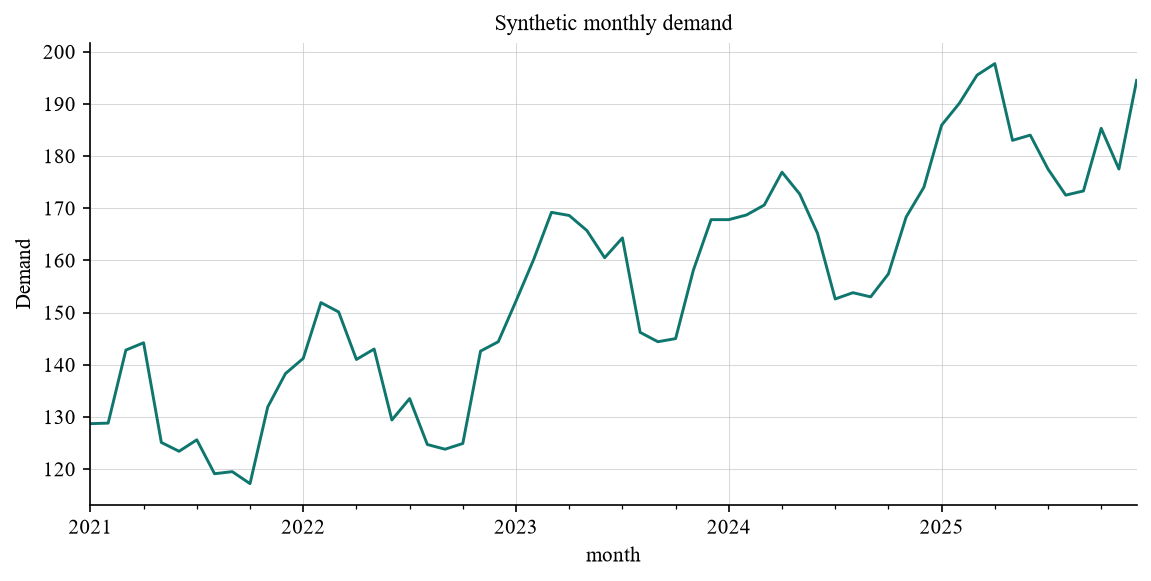

In [3]:
df.set_index("month").plot(
    figsize=(9, 4),
    title="Synthetic monthly demand",
    ylabel="Demand",
    color="#0f766e",
    legend=False,
)

## Chronological validation

The final 12 months are the test period. A random split would allow future
information to leak into the training set.


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import numpy as np

train = df.iloc[:-12].copy()
test = df.iloc[-12:].copy()

# Baseline: same month last year.
seasonal_naive = train["demand"].iloc[-12:].to_numpy()
y_test = test["demand"].to_numpy()

train[["month", "demand"]].tail(2)

,month,demand
46,2024-11-01,168.3
47,2024-12-01,174.0


The seasonal naive forecast repeats the corresponding demand values
from the previous year. It is a strong operational baseline because it preserves
an annual pattern without estimating any parameters.

In [5]:
# A small trend-plus-seasonality regression.
def design_matrix(t):
    return np.column_stack([
        t,
        np.sin(2 * np.pi * t / 12),
        np.cos(2 * np.pi * t / 12),
        np.sin(2 * np.pi * t / 6),
        np.cos(2 * np.pi * t / 6),
    ])

train_t = np.arange(len(train), dtype=float)
future_t = np.arange(len(train), len(train) + len(test), dtype=float)
seasonal_model = LinearRegression().fit(design_matrix(train_t), train["demand"])
seasonal_linear = np.maximum(seasonal_model.predict(design_matrix(future_t)), 0)

The regression uses elapsed time plus two sine-cosine pairs. It can
carry a slow trend and repeating seasonal effects, but it has no information from
the final twelve months during fitting.

In [6]:
def forecast_metrics(prediction):
    safe = np.where(np.abs(y_test) < 1e-9, np.nan, y_test)
    return {
        "MAE": mean_absolute_error(y_test, prediction),
        "MAPE_pct": np.nanmean(np.abs((safe - prediction) / safe)) * 100,
    }

pd.DataFrame({
    "seasonal naive": forecast_metrics(seasonal_naive),
    "seasonal linear": forecast_metrics(seasonal_linear),
}).T

,MAE,MAPE_pct
seasonal naive,19.650000,10.621598
seasonal linear,5.326359,2.860668


The split is chronological: 48 months train the model and the final
12 months remain untouched until evaluation. The seasonal-naive forecast uses
the corresponding months from the previous year rather than copying the latest
value.

## Repeat the forecast across rolling origins

One twelve-month holdout is a narrow test. The next cell moves the forecast
origin forward and evaluates three separate twelve-month windows. This remains a
small teaching sample, but it shows how to inspect forecast stability over time.

In [7]:
def rolling_forecasts(cutoff):
    train_window = df.iloc[:cutoff].copy()
    test_window = df.iloc[cutoff:cutoff + 12].copy()
    horizon = len(test_window)
    naive = train_window["demand"].iloc[-12:].to_numpy()

    train_t = np.arange(len(train_window), dtype=float)
    future_t = np.arange(len(train_window), len(train_window) + horizon, dtype=float)
    model = LinearRegression().fit(
        design_matrix(train_t),
        train_window["demand"],
    )
    linear_forecast = np.maximum(model.predict(design_matrix(future_t)), 0)
    actual = test_window["demand"].to_numpy()
    return {
        "naive_MAE": mean_absolute_error(actual, naive),
        "linear_MAE": mean_absolute_error(actual, linear_forecast),
    }

pd.DataFrame(
    {f"origin_{cutoff}": rolling_forecasts(cutoff) for cutoff in [24, 36, 48]}
).T

,naive_MAE,linear_MAE
origin_24,20.975000,10.984586
origin_36,8.516667,6.788108
origin_48,19.650000,5.326359


**Figure C1 | Actual demand versus two forecasts.** Source: tutorial
calculations. The final 12 months are held out in chronological order.

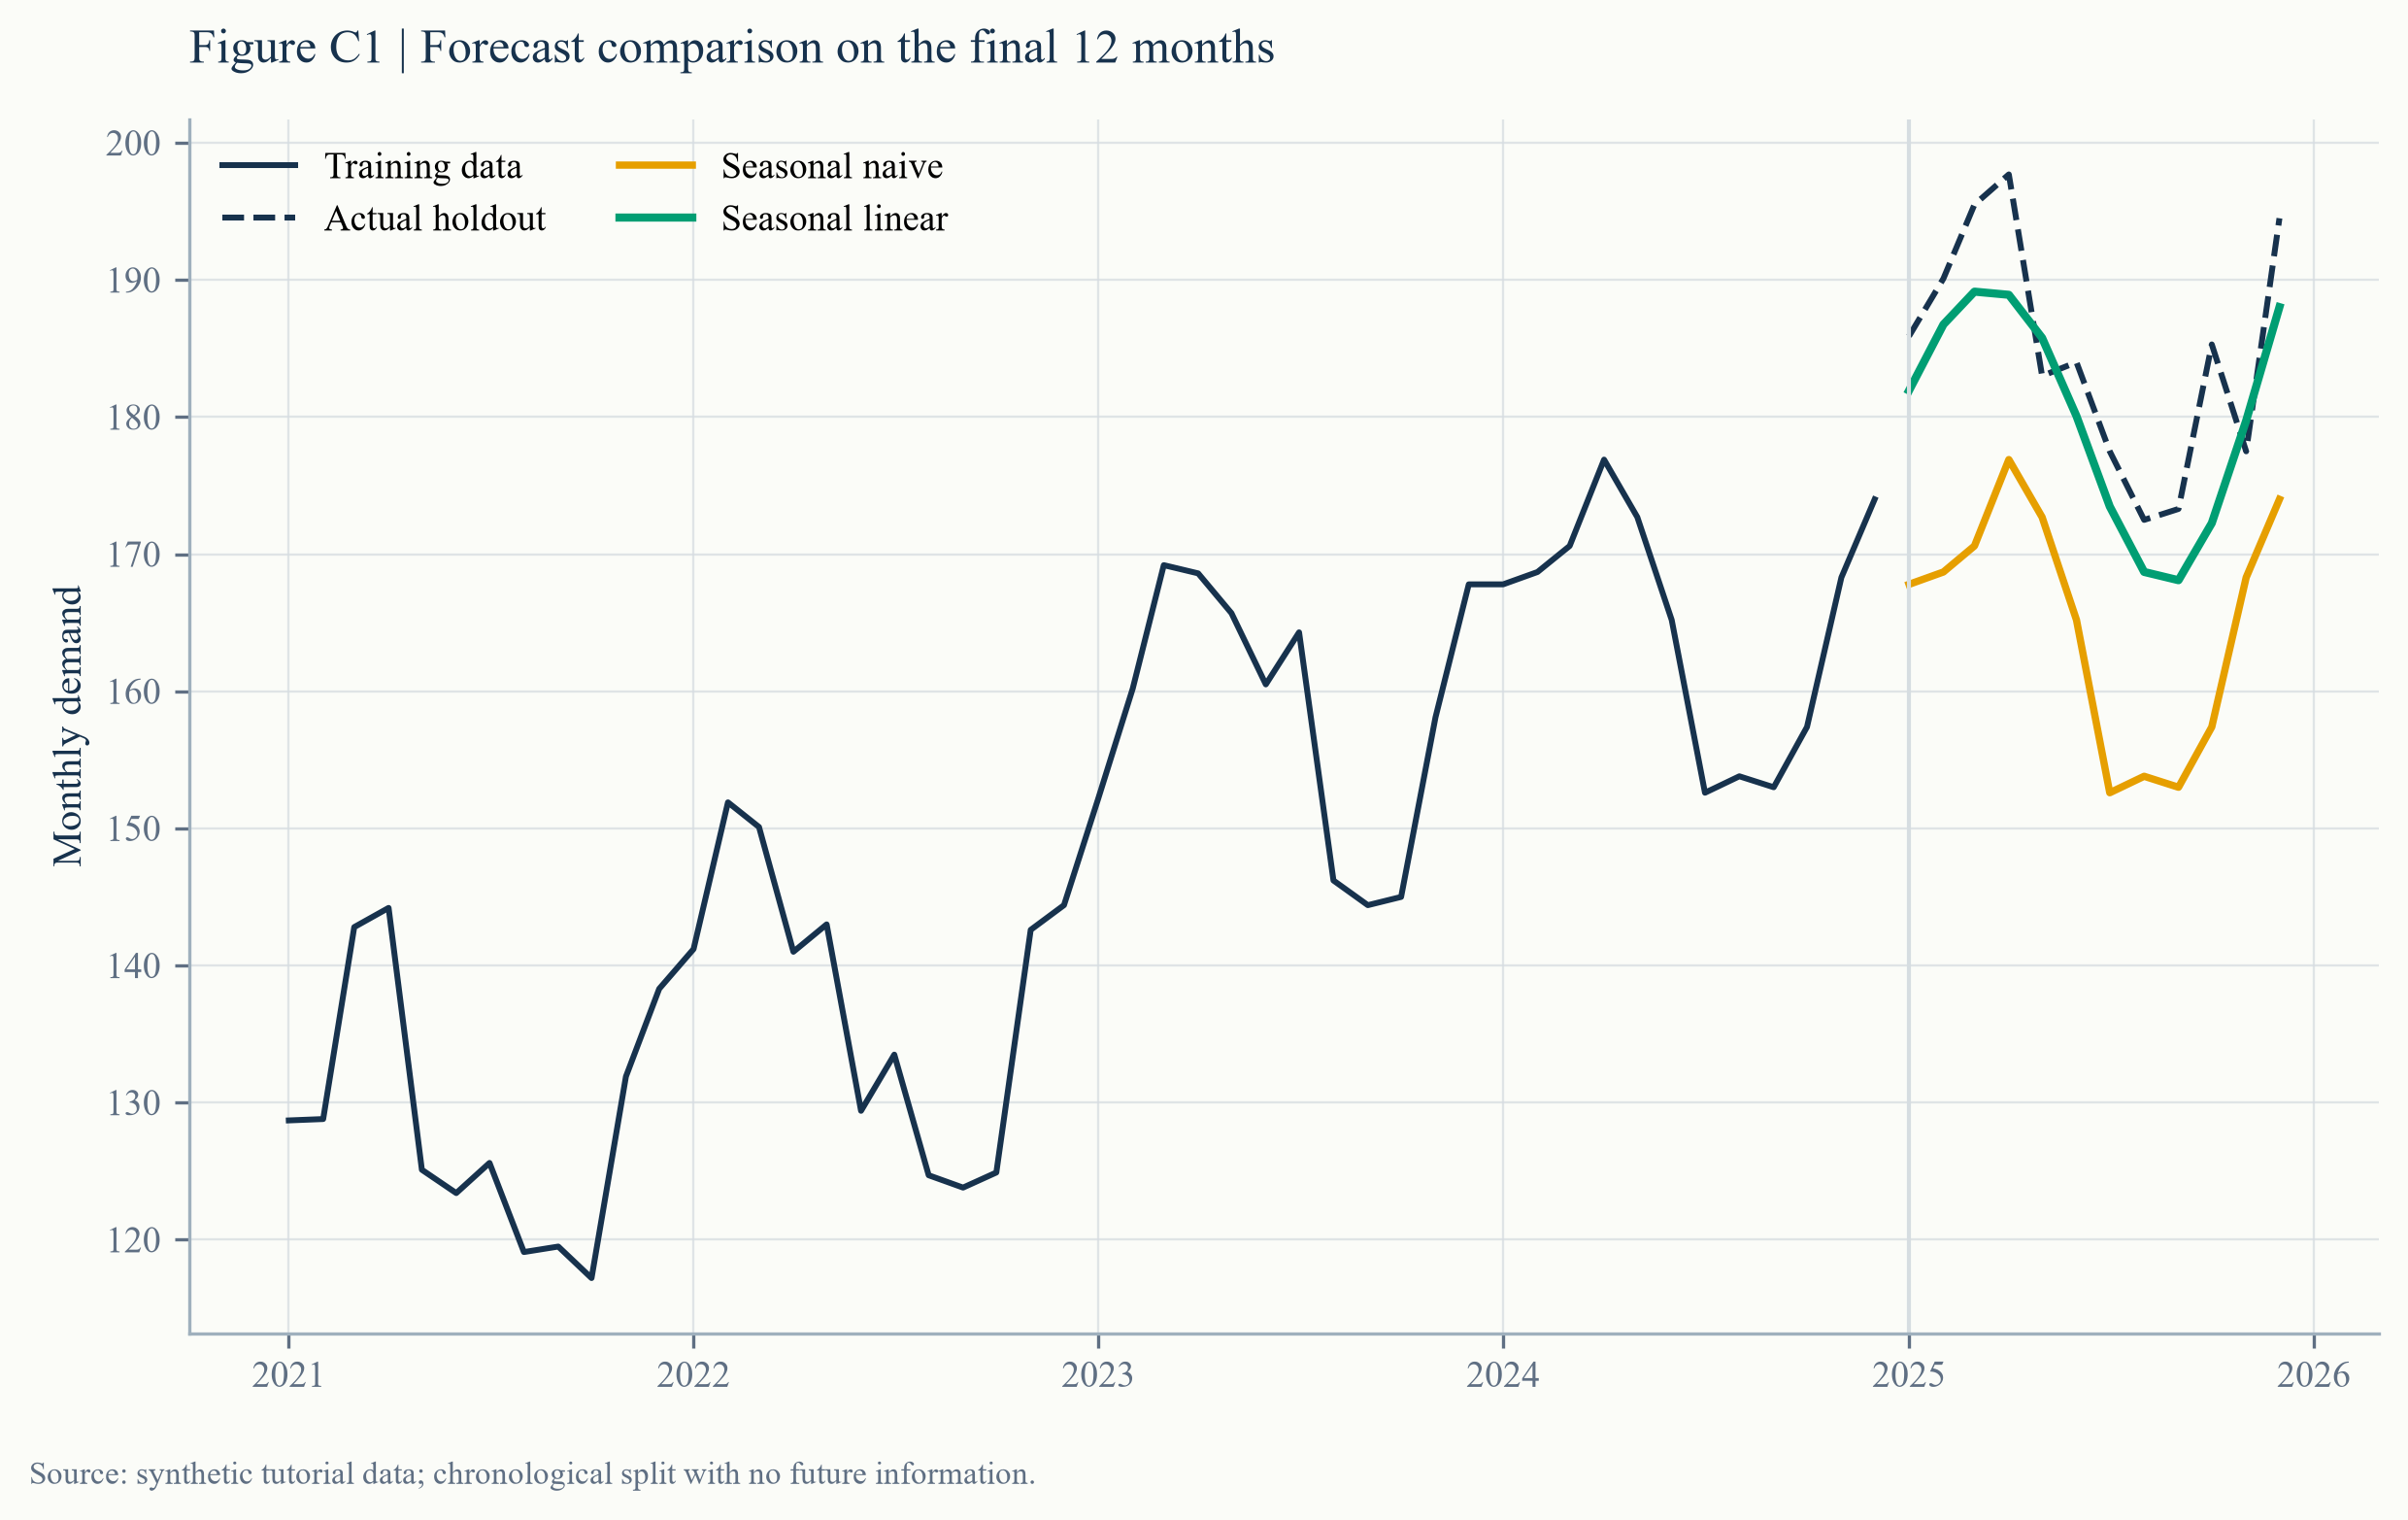

In [8]:
display(Image(filename=str(ROOT / "assets" / "img" / "demand-forecast.png")))

## Interpretation and exercise

MAPE becomes unstable when actual demand approaches zero. For real operational
data, inspect the cost of over- and under-forecasting rather than choosing a
metric by habit.

Exercise: change the holdout from 12 to 6 months and explain why the model
comparison may change.
